# Разведочный анализ данных Friends / MELD

Цель проекта - автоматическая переозвучка видео на другой язык. Наша часть работы - извлечь текст реплик, определить говорящих и временные границы речи, чтобы передать эту разметку на этапы перевода и синтеза.

Для исследования используем датасет MELD, содержащий фрагменты сериала Friends. Каждая запись включает текст реплики, метку говорящего и временные границы. Эмоций и тональности в задаче не используются.

В ходе анализа рассмотрим объём данных, пропуски и дубликаты, ошибки разметки, баланс говорящих и длительность реплик. По результатам определим, какие объекты требуют обработки перед дальнейшим использованием.

In [3]:
import polars as pl

data_dir = '../data/friends_scenes/annotations'

# Загружаем три части датасета и добавляем название части
df = pl.concat([
    pl.read_csv(f'{data_dir}/{split}_sent_emo.csv')
    .with_columns(pl.lit(split).alias('split'))
    for split in ['train', 'dev', 'test']
])

df.head()

Sr No.,Utterance,Speaker,Emotion,Sentiment,Dialogue_ID,Utterance_ID,Season,Episode,StartTime,EndTime,split
i64,str,str,str,str,i64,i64,i64,i64,str,str,str
1,"""also I was the point person on…","""Chandler""","""neutral""","""neutral""",0,0,8,21,"""00:16:16,059""","""00:16:21,731""","""train"""
2,"""You must’ve had your hands ful…","""The Interviewer""","""neutral""","""neutral""",0,1,8,21,"""00:16:21,940""","""00:16:23,442""","""train"""
3,"""That I did. That I did.""","""Chandler""","""neutral""","""neutral""",0,2,8,21,"""00:16:23,442""","""00:16:26,389""","""train"""
4,"""So let’s talk a little bit abo…","""The Interviewer""","""neutral""","""neutral""",0,3,8,21,"""00:16:26,820""","""00:16:29,572""","""train"""
5,"""My duties? All right.""","""Chandler""","""surprise""","""positive""",0,4,8,21,"""00:16:34,452""","""00:16:40,917""","""train"""


In [4]:
# Количество реплик, диалогов, эпизодов и меток говорящих в каждой части датасета

df.group_by('split').agg(
    pl.len().alias('utterances'),
    pl.col('Dialogue_ID').n_unique().alias('dialogues'),
    pl.struct(['Season', 'Episode']).n_unique().alias('episodes'),
    pl.col('Speaker').n_unique().alias('speaker_labels'),
).sort('split')

split,utterances,dialogues,episodes,speaker_labels
str,u32,u32,u32,u32
"""dev""",1109,114,82,47
"""test""",2610,280,143,100
"""train""",9989,1038,188,260


In [5]:
# Проверяем количество и долю пропущенных значений в каждом столбце

df.null_count().transpose(
    include_header=True,
    header_name='column',
    column_names=['missing_count'],
).with_columns(
    (pl.col('missing_count') / df.height * 100).round(2).alias('missing_percent')
)

column,missing_count,missing_percent
str,u32,f64
"""Sr No.""",0,0.0
"""Utterance""",0,0.0
"""Speaker""",0,0.0
"""Emotion""",0,0.0
"""Sentiment""",0,0.0
…,…,…
"""Season""",0,0.0
"""Episode""",0,0.0
"""StartTime""",0,0.0


In [6]:
# Ищем одинаковые исходные аннотации, включая совпадения между частями датасета

duplicate_columns = ['Season', 'Episode', 'StartTime', 'EndTime', 'Speaker', 'Utterance']

duplicates = (
    df.filter(pl.struct(duplicate_columns).is_duplicated())
    .sort(duplicate_columns)
)

duplicates.select(
    'split', 'Dialogue_ID', 'Utterance_ID', *duplicate_columns
)

split,Dialogue_ID,Utterance_ID,Season,Episode,StartTime,EndTime,Speaker,Utterance
str,i64,i64,i64,i64,str,str,str,str
"""train""",698,0,3,25,"""00:16:23,607""","""00:16:25,650""","""Ross""","""Y'know, hey! You’re the one wh…"
"""train""",312,2,3,25,"""00:16:23,607""","""00:16:25,650""","""Ross""","""Y'know, hey! You’re the one wh…"
"""train""",312,3,3,25,"""00:16:25,818""","""00:16:29,862""","""Rachel""","""Yeah, because I was"""
"""train""",698,1,3,25,"""00:16:25,818""","""00:16:29,862""","""Rachel""","""Yeah, because I was"""
"""train""",698,6,3,25,"""00:17:07,609""","""00:17:08,735""","""Ross""","""What?!"""
…,…,…,…,…,…,…,…,…
"""train""",725,3,7,22,"""00:15:59,208""","""00:16:03,836""","""Phoebe""","""Wow! Nice! Manly and also kind…"
"""train""",376,0,7,22,"""0:15:45,527""","""0:15:46,445""","""Joey""","""Hey Pheebs!"""
"""train""",725,0,7,22,"""0:15:45,527""","""0:15:46,445""","""Joey""","""Hey Pheebs!"""


In [8]:
# Считаем повторы аннотаций и выделяем совпадения между частями датасета

duplicate_groups = duplicates.group_by(duplicate_columns).agg(
    pl.len().alias('copies'),
    pl.col('split').unique().sort().alias('splits'),
)

duplicate_groups.select(
    pl.len().alias('duplicate_groups'),
    (pl.col('copies') - 1).sum().alias('extra_rows'),
    (pl.col('splits').list.len() > 1).sum().alias('cross_split_groups'),
)

duplicate_groups,extra_rows,cross_split_groups
u32,u32,u32
11,11,1


In [10]:
# Длительности реплик

df = df.with_columns(
    (
        pl.col('EndTime').str.replace(',', '.').str.to_time('%H:%M:%S%.f')
        - pl.col('StartTime').str.replace(',', '.').str.to_time('%H:%M:%S%.f')
    ).dt.total_milliseconds().truediv(1000).alias('duration_seconds')
)

# Кандидаты на ручную проверку

df.filter(
    (pl.col('duration_seconds') <= 0)
    | (pl.col('duration_seconds') > 30)
).select(
    'split', 'Dialogue_ID', 'Utterance_ID',
    'Speaker', 'Utterance', 'duration_seconds',
).sort('duration_seconds')

split,Dialogue_ID,Utterance_ID,Speaker,Utterance,duration_seconds
str,i64,i64,str,str,f64
"""test""",155,3,"""Rachel""","""Oh my God.""",0.0
"""train""",309,0,"""Chandler""","""Kathy! Kathy! Hi!! Kathy! Kath…",41.04
"""test""",220,0,"""Phoebe""","""What’s that smell?""",235.068
"""test""",38,4,"""Student""","""Oh it’s great, it’s a role on""",304.94


In [11]:
# Исключаем три объекта с подтверждёнными ошибками разметки

broken_objects = pl.DataFrame({
    'split': ['test', 'test', 'test'],
    'Dialogue_ID': [38, 155, 220],
    'Utterance_ID': [4, 3, 0],
})

clean_df = df.join(
    broken_objects,
    on=['split', 'Dialogue_ID', 'Utterance_ID'],
    how='anti',
)

clean_df.select(pl.len().alias('remaining_utterances'))

remaining_utterances
u32
13705


In [12]:
# Метки, которые обозначают группу говорящих

clean_df.filter(
    (pl.col('Speaker') == 'All')
    | pl.col('Speaker').str.contains(r'\band\b')
).group_by('Speaker').agg(
    pl.len().alias('utterances')
).sort('utterances', descending=True)

Speaker,utterances
str,u32
"""All""",51
"""Ross and Rachel""",3
"""Phoebe and Rachel""",1
"""Monica and Ross""",1
"""Ross and Joey""",1
…,…
"""Joey and Chandler""",1
"""Ross and Chandler""",1
"""Rachel and Phoebe""",1


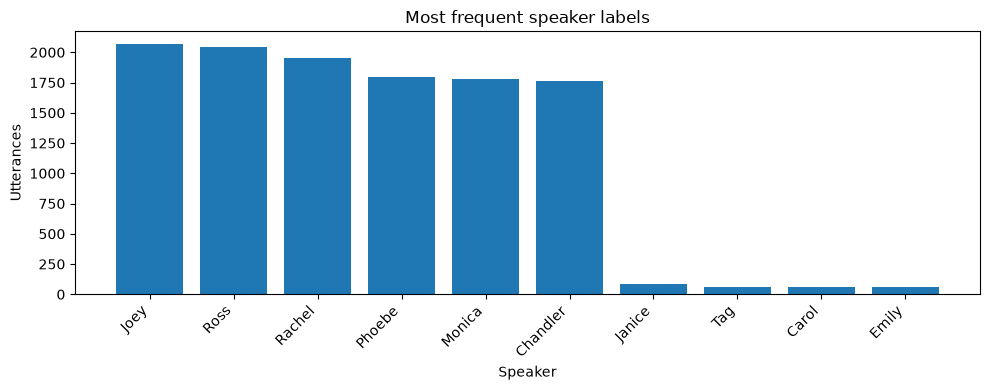

Speaker,utterances,percent
str,u32,f64
"""Joey""",2070,15.1
"""Ross""",2048,14.94
"""Rachel""",1954,14.26
"""Phoebe""",1796,13.1
"""Monica""",1782,13.0
"""Chandler""",1763,12.86
"""Janice""",89,0.65
"""Tag""",60,0.44
"""Carol""",60,0.44


In [13]:
import matplotlib.pyplot as plt

# Считаем реплики для каждой метки говорящего
speaker_counts = (
    clean_df.group_by('Speaker')
    .agg(pl.len().alias('utterances'))
    .sort('utterances', descending=True)
    .with_columns(
        (pl.col('utterances') / clean_df.height * 100).round(2).alias('percent')
    )
)

# Показываем десять наиболее частых меток
top_speakers = speaker_counts.head(10)

plt.figure(figsize=(10, 4))
plt.bar(top_speakers['Speaker'].to_list(), top_speakers['utterances'].to_list())
plt.xlabel('Speaker')
plt.ylabel('Utterances')
plt.title('Most frequent speaker labels')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

top_speakers

In [14]:
# Основные статистики длительности после исключения сломанных объектов

clean_df.select(
    pl.len().alias('utterances'),
    pl.col('duration_seconds').min().alias('min_seconds'),
    pl.col('duration_seconds').max().alias('max_seconds'),
    pl.col('duration_seconds').mean().round(3).alias('mean_seconds'),
    pl.col('duration_seconds').median().round(3).alias('median_seconds'),
)

utterances,min_seconds,max_seconds,mean_seconds,median_seconds
u32,f64,f64,f64,f64
13705,0.006,41.04,3.13,2.46


In [15]:
# Сравниваем длительность реплик шести основных персонажей

main_speakers = ['Joey', 'Ross', 'Rachel', 'Phoebe', 'Monica', 'Chandler']

clean_df.filter(
    pl.col('Speaker').is_in(main_speakers)
).group_by('Speaker').agg(
    pl.len().alias('utterances'),
    pl.col('duration_seconds').min().round(3).alias('min_seconds'),
    pl.col('duration_seconds').max().round(3).alias('max_seconds'),
    pl.col('duration_seconds').mean().round(3).alias('mean_seconds'),
    pl.col('duration_seconds').median().round(3).alias('median_seconds'),
).sort('utterances', descending=True)

Speaker,utterances,min_seconds,max_seconds,mean_seconds,median_seconds
str,u32,f64,f64,f64,f64
"""Joey""",2070,0.084,22.939,3.09,2.46
"""Ross""",2048,0.084,25.775,3.271,2.502
"""Rachel""",1954,0.006,28.527,3.096,2.418
"""Phoebe""",1796,0.084,20.12,3.129,2.418
"""Monica""",1782,0.083,18.809,3.015,2.418
"""Chandler""",1763,0.084,41.04,3.149,2.46


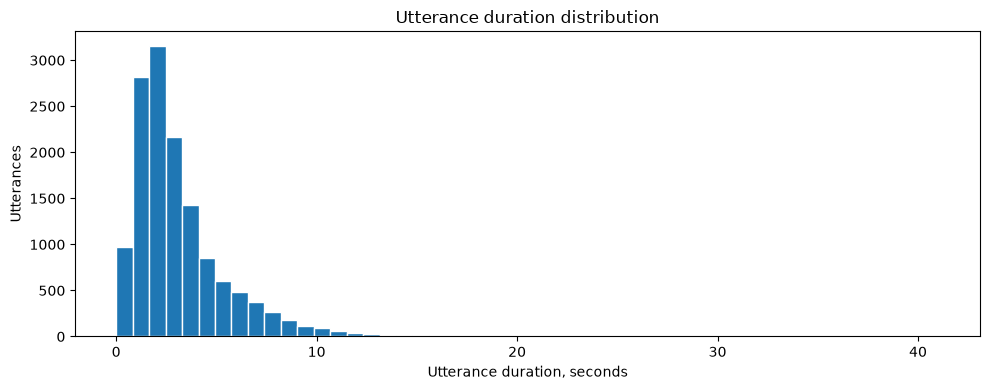

In [16]:
# Распределение длительности реплик после исключения сломанных объектов

plt.figure(figsize=(10, 4))
plt.hist(clean_df['duration_seconds'].to_list(), bins=50, edgecolor='white')
plt.xlabel('Utterance duration, seconds')
plt.ylabel('Utterances')
plt.title('Utterance duration distribution')
plt.tight_layout()
plt.show()

## Выводы

В исходной разметке MELD содержится 13 708 реплик. Пропущенных значений не обнаружено, однако ручная проверка выявила три объекта, содержимое которых не соответствует аннотациям. После их исключения осталось 13 705 объектов.

Шесть основных персонажей составляют большую часть данных. Второстепенные говорящие представлены значительно слабее, поэтому при дальнейшей оценке важно учитывать качество на редко встречающихся персонажах.

После исключения сломанных объектов средняя длительность реплики составляет 3,130 секунды, медианная — 2,460 секунды. Минимальная длительность равна 0,006 секунды, максимальная — 41,040 секунды.

Обнаружены групповые метки говорящих и совпадающие исходные аннотации, в том числе между train и test. Групповые метки необходимо учитывать отдельно, а совпадающий исходный материал — удерживать в одной части выборки при подготовке данных для обучения и оценки.